# Early Wildfire Smoke Detection — and What Minutes Are Worth in Tonnes of CO2

**Global warming course project.** A computer-vision method for *early* wildfire detection, plus a
quantified answer to the question a climate course actually cares about: what does detecting a fire
sooner buy us in avoided emissions?

### The framing

Most "wildfire detection" projects classify photos of **flames**. By the time there are flames big
enough to photograph, the fire is no longer early. Fire lookouts watch for **smoke**, because the
plume is visible minutes before there is anything else to see.

So the question is not *"can a CNN recognise a fire?"* — it obviously can — but:

> **How many minutes after a plume first becomes visible does the detector fire,
> at a false-alarm rate low enough for anyone to actually deploy it?**

We can answer that, because of the dataset.

### Why FIgLib

[FIgLib](http://hpwren.ucsd.edu/HPWREN-FIgLib/) (HPWREN, Southern California) is 523 sequences from
fixed fire-lookout cameras. Each sequence is one real fire: **40 frames before** the plume became
visible, the ignition frame, and **40 frames after**, one per minute. Every filename encodes its
offset in seconds from that moment:

```
20180719_Skyline_sp-n-mobo-c/1465067280_+01680.jpg
                             |- epoch -| |- +1680 s = +28 min -|
```

That signed offset is a free ground-truth clock, and it is what turns "accuracy" into
**time-to-detection**.

### What this notebook produces

| Output | Why it matters |
|---|---|
| Detection probability vs. minutes since ignition | The headline: *how early*, per method |
| Median time-to-detection at a 1% false-alarm rate | One number a fire agency could act on |
| Grad-CAM overlays and a failure gallery | Evidence the model looks at the plume, not an artefact |
| False-alarm rate on clouds from a different camera network | Does it generalise, or memorise these cameras? |
| CO2 sensitivity table | Minutes -> hectares -> tonnes, with honest caveats |

In [2]:
!git clone https://github.com/RaghavPrasanna9207/global-warming repo
%cd repo

Cloning into 'repo'...
remote: Enumerating objects: 18, done.
remote: Counting objects: 100% (18/18), done.
remote: Compressing objects: 100% (17/17), done.
remote: Total 18 (delta 0), reused 18 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (18/18), 1.35 MiB | 15.54 MiB/s, done.
/content/repo/repo


---
## 1. Setup

Runtime -> Change runtime type -> **T4 GPU**. End to end takes roughly 45 minutes.

In [3]:
!pip -q install datasets scikit-learn

In [4]:
import os, re, json, math, time, random, subprocess, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torch.utils.data import Dataset, DataLoader
from PIL import Image
from sklearn.metrics import roc_auc_score, average_precision_score

warnings.filterwarnings("ignore", category=UserWarning)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
FIGDIR = Path("figures"); FIGDIR.mkdir(exist_ok=True)
DATA   = Path("data")

plt.rcParams.update({
    "figure.dpi": 130, "savefig.dpi": 200, "savefig.bbox": "tight",
    "font.size": 9, "axes.grid": True, "grid.alpha": 0.3,
    "axes.spines.top": False, "axes.spines.right": False,
})

print(f"device: {DEVICE}  |  torch {torch.__version__}")
if DEVICE == "cuda":
    print(f"gpu:    {torch.cuda.get_device_name(0)}")
else:
    print("WARNING: no GPU. Runtime -> Change runtime type -> T4 GPU, or expect a very long run.")

device: cuda  |  torch 2.11.0+cu130
gpu:    Tesla T4


### Configuration

`N_SEQUENCES` is the main cost knob: each sequence is about 87 MB and 81 frames. 30 sequences
(~2.6 GB) gives a stable result; drop to 12 for a quick smoke test of the whole pipeline.

In [5]:
N_SEQUENCES  = 30      # sequences to download (~87 MB each)
PER_DATE     = 1       # max cameras per fire -- maximises distinct fires, see section 2
IMG_SIZE     = 448     # NOT 224: early smoke is small and faint, see section 4
REF_LAG_S    = 240     # temporal-stack reference frame: 4 minutes back
REF_TOL_S    = 90      # ...accepted if the nearest real frame is within 90 s of that target
EPOCHS       = 12
BATCH        = 24
LR           = 3e-4
SEEDS        = [0, 1, 2]   # 3 seeds -> mean +/- std on every reported number
TARGET_FPR   = 0.01        # the operating point everything is reported at
PERSISTENCE  = 2           # consecutive frames above threshold required to declare a detection
NUM_WORKERS  = 0 if os.name == "nt" else 2   # >0 hangs in notebooks on Windows (spawn, not fork)

---
## 2. Data

The download script is stdlib-only, deterministic, and caches, so re-running after a Colab
disconnect costs nothing.

**One choice worth flagging** — a real methodological point, not boilerplate. The archive's 523
sequences cover only **338 distinct fires**: a single fire is often filmed by up to 9 cameras at
once. Selecting or splitting on *sequence* name would scatter near-identical views of the same fire
across train and test and inflate every metric. We group by the `YYYYMMDD` date prefix throughout,
and cap how many cameras per fire we download.

In [6]:
if not Path("download_figlib.py").exists():
    raise FileNotFoundError(
        "download_figlib.py not found -- upload it next to this notebook, or clone the project repo."
    )

proc = subprocess.run(
    ["python", "download_figlib.py", "--sequences", str(N_SEQUENCES),
     "--per-date", str(PER_DATE), "--out", str(DATA)],
    capture_output=True, text=True,
)
print(proc.stdout[-3000:])
if proc.returncode != 0:
    print("STDERR:", proc.stderr[-2000:])

fetching archive index ...
525 sequences available; fetching 30 from 30 distinct fires (~2.5 GB)

[  1/30] 20250804_CoolFire_bi-w-mobo-c                  41 frames  ok
[  2/30] 20240131.113006-FIRE-rm-s-mobo-c               80 frames  ok
[  3/30] 20201208_FIRE_om-s-mobo-c                      80 frames  ok
[  4/30] 20200906-BobcatFire-wilson-e-mobo-c            81 frames  ok
[  5/30] 20180827_Holyflareup_sp-e-mobo-c               81 frames  ok
[  6/30] 20250226_PennyFire_ml-w-mobo-c                 81 frames  ok
[  7/30] 20210107_Miguelfire_om-w-mobo-c                80 frames  ok
[  8/30] 20170519_FIRE_rm-w-mobo-c                      81 frames  ok
[  9/30] 20230725.143718-FIRE-sm-n-mobo-c               80 frames  ok
[ 10/30] 20260502_MissionFire_rm-e-mobo-c               81 frames  ok
[ 11/30] 20241031_MontezumaFire_sm-w-mobo-c             80 frames  ok
[ 12/30] 20200905_ValleyFire_lp-n-mobo-c                73 frames  ok
[ 13/30] 20240622_Border58Fire_om-w-mobo-c              81 fra

### 2.1 Frame index

One row per frame. `offset_s` is the signed second-offset parsed from the filename;
`label = 1` once the plume is visible (`offset_s >= 0`).

In [7]:
FRAME_RE = re.compile(r"^(\d+)_([+-]\d+)\.jpg$")

rows = []
for seq_dir in sorted(p for p in DATA.iterdir() if p.is_dir()):
    for f in sorted(seq_dir.glob("*.jpg")):
        m = FRAME_RE.match(f.name)
        if not m:
            continue
        offset_s = int(m.group(2))
        rows.append({
            "sequence": seq_dir.name,
            "fire":     seq_dir.name[:8],           # YYYYMMDD -- the grouping key
            "path":     str(f),
            "offset_s": offset_s,
            "minute":   int(round(offset_s / 60)),  # offsets jitter 58-62 s; round to a minute
            "label":    int(offset_s >= 0),
        })

frames = pd.DataFrame(rows).sort_values(["sequence", "offset_s"]).reset_index(drop=True)

print(f"{len(frames)} frames | {frames.sequence.nunique()} sequences | {frames.fire.nunique()} distinct fires")
print(f"labels: {frames.label.sum()} post-ignition / {(1 - frames.label).sum()} pre-ignition")
print(f"minute range: {frames.minute.min():+d} .. {frames.minute.max():+d}")
frames.head(3)

2330 frames | 30 sequences | 30 distinct fires
labels: 1190 post-ignition / 1140 pre-ignition
minute range: -40 .. +40


,sequence,fire,path,offset_s,minute,label
0,20160619_FIRE_lp-e-iqeye,20160619,data/20160619_FIRE_lp-e-iqeye/1466357053_-0240...,-2400,-40,0
1,20160619_FIRE_lp-e-iqeye,20160619,data/20160619_FIRE_lp-e-iqeye/1466357173_-0228...,-2280,-38,0
2,20160619_FIRE_lp-e-iqeye,20160619,data/20160619_FIRE_lp-e-iqeye/1466357293_-0216...,-2160,-36,0


### 2.2 Attaching the reference frame

The temporal-stack input (section 4) needs a view of the *same scene 4 minutes earlier*. Frame
spacing is nominally 60 s but actually drifts between 58 s and 62 s, and some sequences drop frames
outright (one had a 121 s gap). So we match the reference by **timestamp**, not by counting back
4 rows — index arithmetic would silently pair the wrong frames wherever a frame is missing.

Frames with no reference within tolerance — the opening few of every sequence — are dropped.

In [8]:
def attach_reference(df, lag_s=REF_LAG_S, tol_s=REF_TOL_S):
    out = []
    for _, g in df.groupby("sequence", sort=False):
        g = g.sort_values("offset_s")
        offs, paths = g.offset_s.to_numpy(), g.path.to_numpy()
        targets = offs - lag_s
        idx = np.abs(offs[None, :] - targets[:, None]).argmin(axis=1)   # nearest real frame
        out.append(g.assign(ref_path=paths[idx], ref_err_s=np.abs(offs[idx] - targets)))
    r = pd.concat(out)
    kept = r[r.ref_err_s <= tol_s].reset_index(drop=True)
    print(f"{len(kept)}/{len(r)} frames have a reference within {tol_s}s of t-{lag_s}s "
          f"(dropped {len(r) - len(kept)}: the opening frames of each sequence)")
    return kept

paired = attach_reference(frames)
paired.head(3)

2241/2330 frames have a reference within 90s of t-240s (dropped 89: the opening frames of each sequence)


,sequence,fire,path,offset_s,minute,label,ref_path,ref_err_s
0,20160619_FIRE_lp-e-iqeye,20160619,data/20160619_FIRE_lp-e-iqeye/1466357293_-0216...,-2160,-36,0,data/20160619_FIRE_lp-e-iqeye/1466357053_-0240...,0
1,20160619_FIRE_lp-e-iqeye,20160619,data/20160619_FIRE_lp-e-iqeye/1466357413_-0204...,-2040,-34,0,data/20160619_FIRE_lp-e-iqeye/1466357173_-0228...,0
2,20160619_FIRE_lp-e-iqeye,20160619,data/20160619_FIRE_lp-e-iqeye/1466357533_-0192...,-1920,-32,0,data/20160619_FIRE_lp-e-iqeye/1466357293_-0216...,0


### 2.3 Splitting by fire — the part that decides whether any of the numbers mean anything

Frames one minute apart from the same camera are near-duplicates. Split at the frame level and the
model sees each test frame's neighbours during training; AUROC climbs to ~0.99 and means nothing.

We split on the **fire date**, so every camera angle and every frame of a given fire lands entirely
in one split. The assertion is the guard.

In [9]:
fires = sorted(paired.fire.unique())
np.random.default_rng(0).shuffle(fires)

n      = len(fires)
n_test = max(1, round(0.25 * n))
n_val  = max(1, round(0.20 * n))
test_fires  = set(fires[:n_test])
val_fires   = set(fires[n_test:n_test + n_val])
train_fires = set(fires[n_test + n_val:])

def subset(fs): return paired[paired.fire.isin(fs)].reset_index(drop=True)
train_df, val_df, test_df = subset(train_fires), subset(val_fires), subset(test_fires)

# The guard. If this ever trips, every metric below is meaningless.
assert not (train_fires & val_fires), "fire leakage: train/val"
assert not (train_fires & test_fires), "fire leakage: train/test"
assert not (val_fires & test_fires), "fire leakage: val/test"
assert set(train_df.sequence).isdisjoint(test_df.sequence), "sequence leakage"

for name, df, fs in [("train", train_df, train_fires),
                     ("val", val_df, val_fires),
                     ("test", test_df, test_fires)]:
    print(f"{name:5s} {len(fs):3d} fires  {df.sequence.nunique():3d} sequences  "
          f"{len(df):5d} frames  ({df.label.mean():.0%} post-ignition)")

train  16 fires   16 sequences   1195 frames  (52% post-ignition)
val     6 fires    6 sequences    464 frames  (52% post-ignition)
test    8 fires    8 sequences    582 frames  (55% post-ignition)


---
## 3. Look at the data before modelling anything

Two sanity checks that are worth the cell: what a plume actually looks like at t = -10, 0, +5, +20
minutes, and how little of the frame it occupies early on.

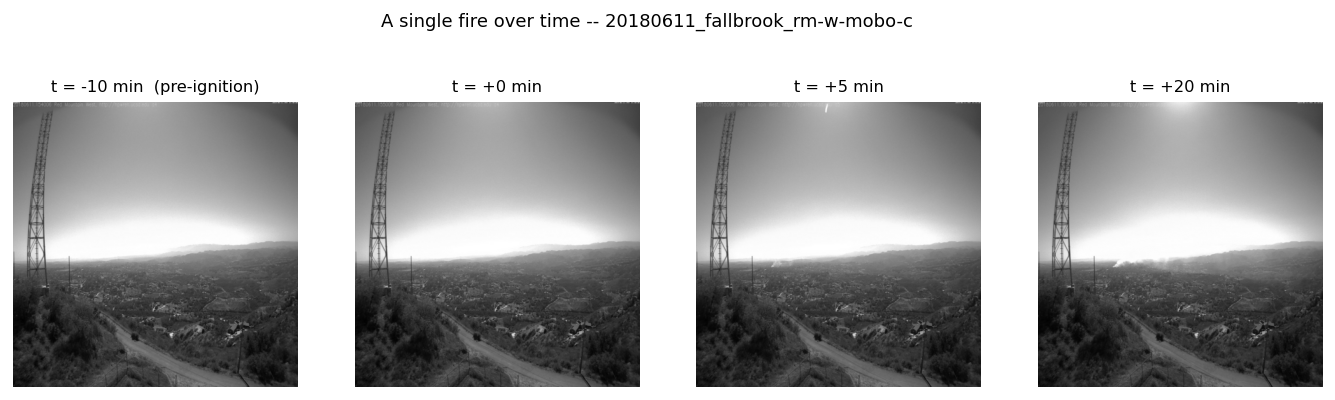

Note how little of the frame the plume occupies at t = 0 and t = +5.
That is the entire difficulty of *early* detection, and the reason for section 4.


In [10]:
def load_gray(path, size=IMG_SIZE):
    # FIgLib mixes monochrome (-mobo-m) and colour (-mobo-c / -iqeye) cameras. Converting
    # everything to grayscale makes the two interchangeable, and costs nothing: smoke is
    # essentially achromatic, so colour carries little signal for this task.
    img = Image.open(path).convert("L").resize((size, size), Image.BILINEAR)
    return np.asarray(img, dtype=np.float32) / 255.0

demo_seq = test_df.sequence.iloc[0]
g = paired[paired.sequence == demo_seq].sort_values("minute")

fig, axes = plt.subplots(1, 4, figsize=(13, 3.4))
for ax, target in zip(axes, [-10, 0, 5, 20]):
    row = g.iloc[(g.minute - target).abs().argmin()]
    ax.imshow(load_gray(row.path), cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"t = {row.minute:+d} min" + ("  (pre-ignition)" if row.minute < 0 else ""), fontsize=9)
    ax.axis("off")
fig.suptitle(f"A single fire over time -- {demo_seq}", y=1.02, fontsize=10)
fig.savefig(FIGDIR / "fig1_sequence_over_time.png")
plt.show()

print("Note how little of the frame the plume occupies at t = 0 and t = +5.")
print("That is the entire difficulty of *early* detection, and the reason for section 4.")

---
## 4. Method

### 4.1 The problem with the obvious approach

The default recipe — resize to 224x224, fine-tune a CNN — is structurally unable to be early here.
FIgLib frames are 2048x1536 or 3072x2048 depending on the camera. An early plume might span 60 px.
Downscale to 224 and it survives as roughly 4-7 px of low-contrast haze, which does not survive the
first pooling layer. A single-frame
224 px classifier can learn "this scene is on fire" long after ignition, but it cannot be *early*.

Two fixes, both cheap:

**1. Resolution.** 448x448 instead of 224x224. ResNet-18 handles it fine on a T4.

**2. Temporal stacking.** These are *fixed* cameras — the background is free information. For the
frame at time t we build a 3-channel tensor:

| Channel | Content |
|---|---|
| 0 | `gray(t)` — the current view |
| 1 | `gray(t - 4 min)` — the same scene, before |
| 2 | `abs(gray(t) - gray(t - 4 min))` — what changed |

This drops straight into ImageNet-pretrained weights with no architecture surgery: it is still a
3-channel image tensor. A faint plume that is nearly invisible in channel 0 is obvious in channel 2,
because it is the only thing in the scene that appeared.

It is not free of confounders — clouds drift, shadows move, cameras occasionally jitter — which is
exactly why we still need a learned model rather than a threshold on the difference image. The
classical baseline in section 7.3 is there to measure how much that learning is worth.

### 4.2 The two arms

| Arm | Input | Purpose |
|---|---|---|
| **A. Single-frame** | `gray(t)` repeated across 3 channels | Baseline. Expected to be late. |
| **B. Temporal-stack** | the 3-channel stack above | Hypothesis: detects earlier at equal false-alarm rate |

Same backbone, same schedule, same data, same seeds. The *only* difference is the input transform,
which is what makes the comparison a fair test of the idea rather than of tuning effort.

In [11]:
class FrameDataset(Dataset):
    # mode="single" -> arm A, mode="stack" -> arm B.
    def __init__(self, df, mode, size=IMG_SIZE, train=False, norm=None):
        self.df, self.mode, self.size, self.train = df.reset_index(drop=True), mode, size, train
        self.norm = norm

    def __len__(self): return len(self.df)

    def raw(self, i):
        row = self.df.iloc[i]
        cur = load_gray(row.path, self.size)
        if self.mode == "single":
            x = np.stack([cur, cur, cur])
        else:
            ref = load_gray(row.ref_path, self.size)
            x = np.stack([cur, ref, np.abs(cur - ref)])
        return x, float(row.label)

    def __getitem__(self, i):
        x, y = self.raw(i)
        # Horizontal flip only. No vertical flip: smoke rises, and that asymmetry is signal
        # we would rather the model keep. Flip is applied to all channels together so the
        # current frame and its reference stay registered.
        if self.train and random.random() < 0.5:
            x = x[:, :, ::-1].copy()
        x = torch.from_numpy(x)
        if self.norm is not None:
            x = (x - self.norm[0][:, None, None]) / self.norm[1][:, None, None]
        return x, torch.tensor(y)


def channel_stats(df, mode, n=200, seed=0):
    # The stack's channel 2 (absolute difference) is mostly near zero, so ImageNet's
    # statistics are wrong for it. Measure our own on a sample of the training set.
    ds = FrameDataset(df, mode)
    idx = np.random.default_rng(seed).choice(len(ds), size=min(n, len(ds)), replace=False)
    xs = np.stack([ds.raw(int(i))[0] for i in idx])
    mean = torch.tensor(xs.mean(axis=(0, 2, 3)), dtype=torch.float32)
    std  = torch.tensor(xs.std(axis=(0, 2, 3)).clip(1e-3), dtype=torch.float32)
    print(f"{mode:7s} channel mean {mean.numpy().round(4)}  std {std.numpy().round(4)}")
    return mean, std

NORM = {m: channel_stats(train_df, m) for m in ("single", "stack")}

single  channel mean [0.4231 0.4231 0.4231]  std [0.2451 0.2451 0.2451]
stack   channel mean [0.4231 0.422  0.0184]  std [0.2451 0.245  0.0483]


### 4.3 What the network actually sees

Worth showing in the report: the same moment as arm A sees it versus arm B's difference channel.

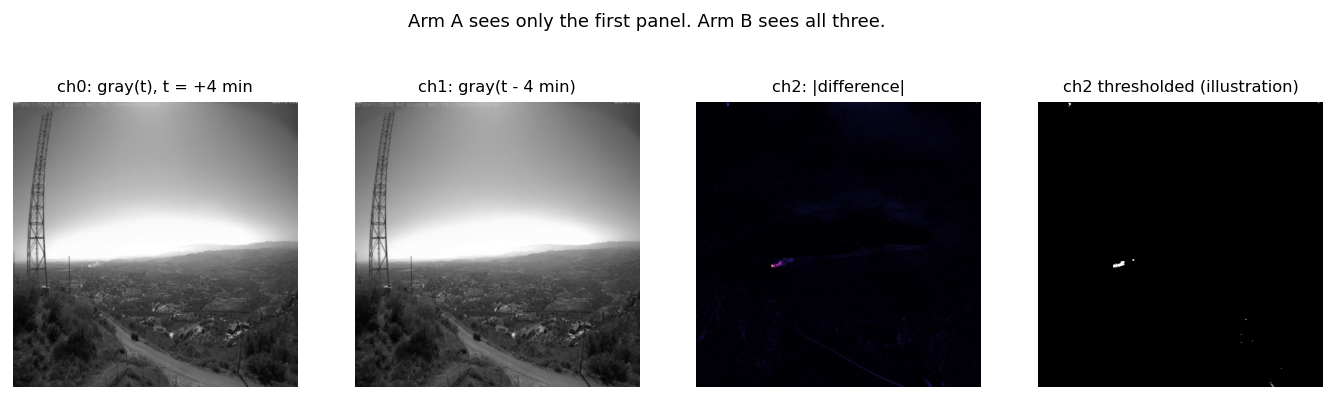

In [12]:
g = paired[paired.sequence == demo_seq].sort_values("minute")
row = g.iloc[(g.minute - 4).abs().argmin()]   # 4 minutes after the plume appeared

cur = load_gray(row.path); ref = load_gray(row.ref_path); diff = np.abs(cur - ref)

fig, axes = plt.subplots(1, 4, figsize=(13, 3.4))
for ax, (im, title, kw) in zip(axes, [
    (cur,  f"ch0: gray(t), t = {row.minute:+d} min", dict(cmap="gray", vmin=0, vmax=1)),
    (ref,  "ch1: gray(t - 4 min)",                   dict(cmap="gray", vmin=0, vmax=1)),
    (diff, "ch2: |difference|",                      dict(cmap="magma")),
    (diff > 0.06, "ch2 thresholded (illustration)",  dict(cmap="gray")),
]):
    ax.imshow(im, **kw); ax.set_title(title, fontsize=9); ax.axis("off")
fig.suptitle("Arm A sees only the first panel. Arm B sees all three.", y=1.02, fontsize=10)
fig.savefig(FIGDIR / "fig2_temporal_stack.png")
plt.show()

---
## 5. Training

ResNet-18 pretrained on ImageNet, final layer replaced by a single logit, BCE loss, AdamW with
cosine decay, mixed precision. Small enough that three seeds per arm costs minutes, which is what
lets us put error bars on every number instead of reporting one lucky run.

In [13]:
def make_model():
    m = torchvision.models.resnet18(weights=torchvision.models.ResNet18_Weights.IMAGENET1K_V1)
    m.fc = nn.Linear(m.fc.in_features, 1)
    return m.to(DEVICE)


@torch.no_grad()
def predict(model, df, mode, batch=BATCH * 2):
    model.eval()
    dl = DataLoader(FrameDataset(df, mode, norm=NORM[mode]), batch_size=batch, num_workers=NUM_WORKERS)
    out = []
    for x, _ in dl:
        with torch.autocast("cuda", enabled=DEVICE == "cuda"):
            out.append(torch.sigmoid(model(x.to(DEVICE)).squeeze(1)).float().cpu())
    return torch.cat(out).numpy()


def train_arm(mode, seed, epochs=EPOCHS, verbose=True):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

    model = make_model()
    dl = DataLoader(FrameDataset(train_df, mode, train=True, norm=NORM[mode]),
                    batch_size=BATCH, shuffle=True, num_workers=NUM_WORKERS, drop_last=True)
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs * len(dl))
    scaler = torch.amp.GradScaler(enabled=DEVICE == "cuda")
    lossf = nn.BCEWithLogitsLoss()

    t0 = time.time()
    for ep in range(epochs):
        model.train(); running = 0.0
        for x, y in dl:
            x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
            opt.zero_grad(set_to_none=True)
            with torch.autocast("cuda", enabled=DEVICE == "cuda"):
                loss = lossf(model(x).squeeze(1), y)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()
            running += loss.item() * len(y)
        if verbose and (ep % 3 == 2 or ep == epochs - 1):
            auc = roc_auc_score(val_df.label, predict(model, val_df, mode))
            print(f"    epoch {ep+1:2d}/{epochs}  loss {running/len(dl.dataset):.4f}  val AUROC {auc:.4f}")
    if verbose:
        print(f"    trained in {time.time()-t0:.0f}s")
    return model

In [14]:
models, scores = {}, {}
for mode in ("single", "stack"):
    for seed in SEEDS:
        print(f"\n=== arm {'A (single-frame)' if mode == 'single' else 'B (temporal stack)'} | seed {seed} ===")
        m = train_arm(mode, seed)
        models[(mode, seed)] = m
        scores[(mode, seed)] = {"val": predict(m, val_df, mode), "test": predict(m, test_df, mode)}
print("\ndone")


=== arm A (single-frame) | seed 0 ===
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 195MB/s]


    epoch  3/12  loss 0.2376  val AUROC 0.6388
    epoch  6/12  loss 0.1002  val AUROC 0.5662
    epoch  9/12  loss 0.0363  val AUROC 0.5908
    epoch 12/12  loss 0.0208  val AUROC 0.6004
    trained in 665s

=== arm A (single-frame) | seed 1 ===
    epoch  3/12  loss 0.2546  val AUROC 0.5336
    epoch  6/12  loss 0.0847  val AUROC 0.5585
    epoch  9/12  loss 0.0388  val AUROC 0.5585
    epoch 12/12  loss 0.0179  val AUROC 0.5549
    trained in 680s

=== arm A (single-frame) | seed 2 ===
    epoch  3/12  loss 0.2139  val AUROC 0.6037
    epoch  6/12  loss 0.0926  val AUROC 0.6462
    epoch  9/12  loss 0.0387  val AUROC 0.6838
    epoch 12/12  loss 0.0241  val AUROC 0.6809
    trained in 670s

=== arm B (temporal stack) | seed 0 ===
    epoch  3/12  loss 0.1523  val AUROC 0.6581
    epoch  6/12  loss 0.0480  val AUROC 0.6939
    epoch  9/12  loss 0.0149  val AUROC 0.6912
    epoch 12/12  loss 0.0087  val AUROC 0.6725
    trained in 1235s

=== arm B (temporal stack) | seed 1 ===
    epo

---
## 6. Evaluation

### 6.1 Choosing an operating point, honestly

A detector is only useful at a false-alarm rate an operator will tolerate. A camera network firing
even a few false alerts per camera per day is switched off by the humans who receive them, so we fix
the operating point first and report everything there:

> **Threshold = the value that gives a 1% false-positive rate on pre-ignition frames of the
> validation fires.**

Chosen on validation, applied unchanged to test. Never tuned on test.

In [15]:
def threshold_at_fpr(y, s, target=TARGET_FPR):
    # Lowest threshold whose false-positive rate on true negatives is <= target.
    # Taking the k-th largest negative score (1-indexed) admits exactly k false
    # positives; using neg[k] instead would admit k+1 and quietly overshoot.
    neg = np.sort(s[y == 0])[::-1]
    k = max(1, int(np.floor(target * len(neg))))
    return float(neg[min(k, len(neg)) - 1])


def frame_metrics(mode, seed):
    sc = scores[(mode, seed)]
    tau = threshold_at_fpr(val_df.label.to_numpy(), sc["val"])
    y, s = test_df.label.to_numpy(), sc["test"]
    pre = s[y == 0]
    return {
        "AUROC": roc_auc_score(y, s),
        "AP": average_precision_score(y, s),
        "tau": tau,
        "test FPR": float((pre >= tau).mean()),
        "test recall": float((s[y == 1] >= tau).mean()),
    }

rows = []
for mode in ("single", "stack"):
    per_seed = pd.DataFrame([frame_metrics(mode, s) for s in SEEDS])
    rows.append(pd.Series({f"{c}": f"{per_seed[c].mean():.3f} +/- {per_seed[c].std():.3f}"
                           for c in per_seed.columns},
                          name="A: single-frame" if mode == "single" else "B: temporal stack"))
frame_table = pd.DataFrame(rows)
print("Frame-level performance on held-out fires (mean +/- std over seeds)\n")
frame_table

Frame-level performance on held-out fires (mean +/- std over seeds)



,AUROC,AP,tau,test FPR,test recall
A: single-frame,0.585 +/- 0.036,0.653 +/- 0.090,0.995 +/- 0.003,0.001 +/- 0.002,0.026 +/- 0.030
B: temporal stack,0.845 +/- 0.035,0.899 +/- 0.019,0.998 +/- 0.003,0.000 +/- 0.000,0.072 +/- 0.044


### 6.2 The metric that actually answers the question

Frame-level AUROC treats a frame at t = +1 min and one at t = +39 min as equally important. For
early detection they could not be less equal. So we simulate what a deployed monitor would do:

1. Walk the sequence forward in time from ignition.
2. Raise an alert at the first minute where the score exceeds tau for **2 consecutive frames**.
   (Real alerting systems use a persistence rule; a single-frame trigger is a false-alarm machine.)
3. Record that minute as the **time to detection** for that fire.

A fire never detected within the 40-minute window counts as censored at 40 min — reported
separately rather than silently dropped, since dropping misses is the easiest way to make a
detector look better than it is.

In [16]:
HORIZON = 40

def time_to_detection(df, s, tau, k=PERSISTENCE, horizon=HORIZON):
    # Returns {sequence: minute of alert or None if never}.
    out = {}
    d = df.assign(score=s)
    for seq, g in d.groupby("sequence"):
        g = g[g.minute >= 0].sort_values("minute")
        above, run, hit = (g.score.to_numpy() >= tau), 0, None
        for minute, a in zip(g.minute.to_numpy(), above):
            run = run + 1 if a else 0
            if run >= k:
                hit = int(minute); break
        out[seq] = hit if (hit is not None and hit <= horizon) else None
    return out


def detection_summary(mode):
    meds, rates, alls = [], [], []
    for seed in SEEDS:
        sc = scores[(mode, seed)]
        tau = threshold_at_fpr(val_df.label.to_numpy(), sc["val"])
        ttd = time_to_detection(test_df, sc["test"], tau)
        hits = [v for v in ttd.values() if v is not None]
        meds.append(np.median(hits) if hits else np.nan)
        rates.append(len(hits) / len(ttd))
        alls.append(ttd)
    return meds, rates, alls

summary, detections = {}, {}
for mode in ("single", "stack"):
    meds, rates, alls = detection_summary(mode)
    detections[mode] = alls
    summary[mode] = {
        "median time to detection (min)": f"{np.nanmean(meds):.1f} +/- {np.nanstd(meds):.1f}",
        "fires detected within 40 min":   f"{np.mean(rates):.0%} +/- {np.std(rates):.0%}",
    }

ttd_table = pd.DataFrame(summary).rename(
    columns={"single": "A: single-frame", "stack": "B: temporal stack"})
print(f"Time to detection, at the 1% false-alarm operating point, {len(test_fires)} held-out fires\n")
ttd_table

Time to detection, at the 1% false-alarm operating point, 8 held-out fires



,A: single-frame,B: temporal stack
median time to detection (min),22.0 +/- 7.0,22.0 +/- 9.3
fires detected within 40 min,8% +/- 6%,25% +/- 18%


### 6.3 The headline figure

Detection probability as a function of minutes since the plume became visible. The left edge is
what "early" means; a curve that only rises at +20 min describes a detector that tells you about
fires you already know about.

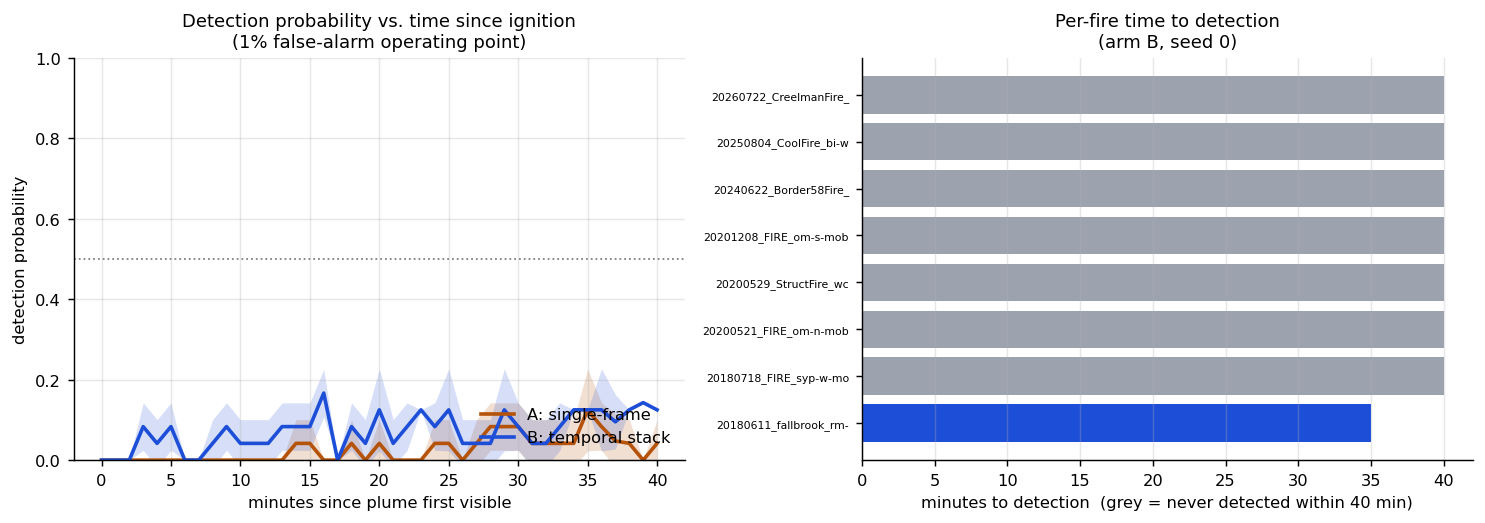

In [17]:
minutes = np.arange(0, HORIZON + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 4.1))

colors = {"single": "#B45309", "stack": "#1D4ED8"}
labels = {"single": "A: single-frame", "stack": "B: temporal stack"}

for mode in ("single", "stack"):
    curves = []
    for seed in SEEDS:
        sc = scores[(mode, seed)]
        tau = threshold_at_fpr(val_df.label.to_numpy(), sc["val"])
        d = test_df.assign(score=sc["test"])
        d = d[d.minute >= 0]
        curves.append([(d[d.minute == mm].score >= tau).mean() if (d.minute == mm).any() else np.nan
                       for mm in minutes])
    c = np.array(curves, dtype=float)
    mean, sd = np.nanmean(c, axis=0), np.nanstd(c, axis=0)
    ax1.plot(minutes, mean, color=colors[mode], lw=2, label=labels[mode])
    ax1.fill_between(minutes, mean - sd, mean + sd, color=colors[mode], alpha=0.18, lw=0)

ax1.axhline(0.5, color="gray", ls=":", lw=1)
ax1.set_xlabel("minutes since plume first visible"); ax1.set_ylabel("detection probability")
ax1.set_title("Detection probability vs. time since ignition\n(1% false-alarm operating point)", fontsize=10)
ax1.set_ylim(0, 1); ax1.legend(frameon=False, loc="lower right")

# Right panel: per-fire time to detection, arm B, seed 0 -- the spread matters as much as the median.
tau0 = threshold_at_fpr(val_df.label.to_numpy(), scores[("stack", 0)]["val"])
ttd0 = time_to_detection(test_df, scores[("stack", 0)]["test"], tau0)
vals = [(k, v if v is not None else HORIZON) for k, v in sorted(ttd0.items(), key=lambda kv: (kv[1] is None, kv[1]))]
ax2.barh(range(len(vals)), [v for _, v in vals],
         color=[colors["stack"] if ttd0[k] is not None else "#9CA3AF" for k, _ in vals])
ax2.set_yticks(range(len(vals)))
ax2.set_yticklabels([k[:22] for k, _ in vals], fontsize=6)
ax2.set_xlabel("minutes to detection  (grey = never detected within 40 min)")
ax2.set_title("Per-fire time to detection\n(arm B, seed 0)", fontsize=10)
ax2.grid(axis="y", alpha=0)

fig.tight_layout()
fig.savefig(FIGDIR / "fig3_detection_vs_time.png")
plt.show()

---
## 7. Is it looking at the plume, or at something else?

A model can hit high AUROC on this dataset for embarrassing reasons: a timestamp burned into the
image, a lens artefact, a slow illumination drift between the pre- and post-ignition halves of a
sequence. Grad-CAM is how we check the model is not cheating.

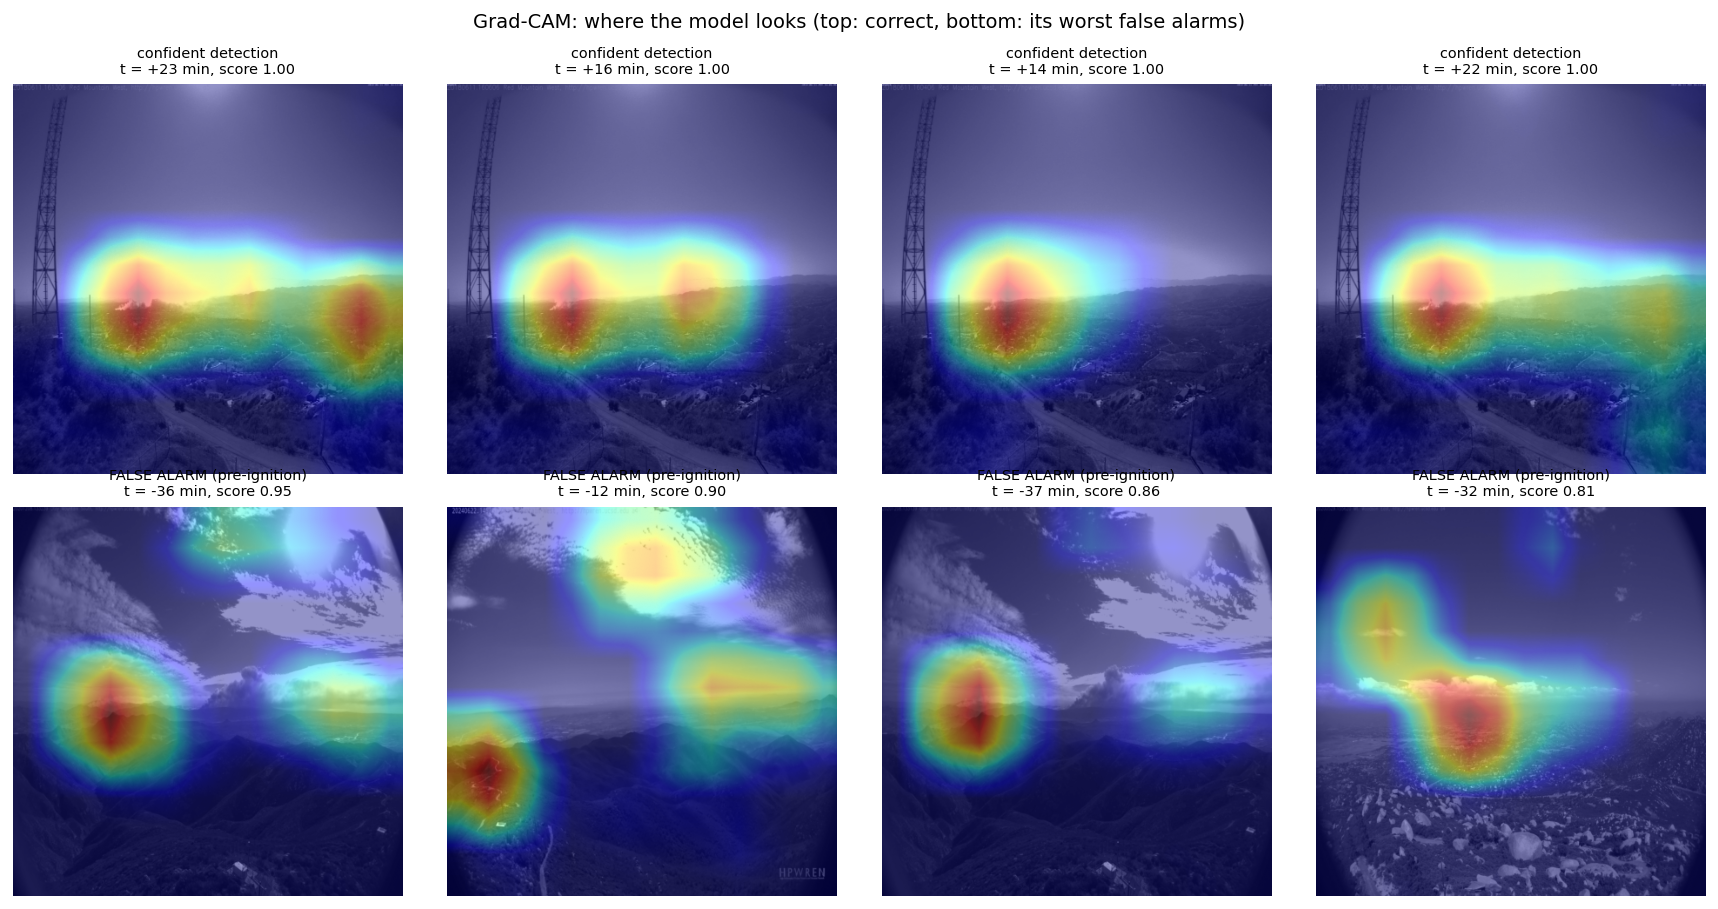

Read the bottom row carefully -- these are the pre-ignition frames the model was most
confident about. Whatever they have in common is this method's real failure mode, and
belongs in the report as a named limitation (cloud bank? haze? camera motion? glare?).


In [18]:
def gradcam(model, x):
    # Standard Grad-CAM on the last residual block. ~20 lines, no extra dependency.
    model.eval()
    feats, grads = {}, {}
    h1 = model.layer4.register_forward_hook(lambda m, i, o: feats.__setitem__("v", o))
    h2 = model.layer4.register_full_backward_hook(lambda m, gi, go: grads.__setitem__("v", go[0]))
    logit = model(x.unsqueeze(0).to(DEVICE)).squeeze()
    model.zero_grad(set_to_none=True); logit.backward()
    h1.remove(); h2.remove()
    w = grads["v"].mean(dim=(2, 3), keepdim=True)
    cam = F.relu((w * feats["v"]).sum(1, keepdim=True))
    cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)
    cam = cam.squeeze().detach().cpu().numpy()
    cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)   # not cam.ptp(): removed in NumPy 2
    return cam, torch.sigmoid(logit).item()


model_b = models[("stack", 0)]
ds_test = FrameDataset(test_df, "stack", norm=NORM["stack"])
sc_b = scores[("stack", 0)]["test"]
tau_b = threshold_at_fpr(val_df.label.to_numpy(), scores[("stack", 0)]["val"])

post = test_df.index[(test_df.label == 1) & (test_df.minute.between(2, 25))].to_numpy()
best = post[np.argsort(-sc_b[post])][:4]                                   # confident detections
worst_fp = test_df.index[(test_df.label == 0)].to_numpy()
worst_fp = worst_fp[np.argsort(-sc_b[worst_fp])][:4]                       # worst false alarms

fig, axes = plt.subplots(2, 4, figsize=(13.5, 7))
for axrow, idxs, title in [(axes[0], best, "confident detection"),
                           (axes[1], worst_fp, "FALSE ALARM (pre-ignition)")]:
    for ax, i in zip(axrow, idxs):
        x, _ = ds_test[int(i)]
        cam, p = gradcam(model_b, x)
        r = test_df.loc[int(i)]
        ax.imshow(load_gray(r.path), cmap="gray", vmin=0, vmax=1)
        ax.imshow(cam, cmap="jet", alpha=0.42)
        ax.set_title(f"{title}\nt = {r.minute:+d} min, score {p:.2f}", fontsize=8)
        ax.axis("off")
fig.suptitle("Grad-CAM: where the model looks (top: correct, bottom: its worst false alarms)", y=0.99)
fig.tight_layout()
fig.savefig(FIGDIR / "fig4_gradcam.png")
plt.show()

print("Read the bottom row carefully -- these are the pre-ignition frames the model was most")
print("confident about. Whatever they have in common is this method's real failure mode, and")
print("belongs in the report as a named limitation (cloud bank? haze? camera motion? glare?).")

### 7.1 Does it generalise, or did it memorise these cameras?

Everything above is Southern California, one camera network, one vendor's optics. A detector that
works only there is not a contribution.

So we test on [`sagecontinuum/smokedataset`](https://huggingface.co/datasets/sagecontinuum/smokedataset)
— a *different* network (Wild Sage Nodes), with a `cloud` class. Clouds are the classic confuser:
white, diffuse, sitting on the horizon. The question is what fraction of clouds our FIgLib-trained
model calls smoke.

**A caveat that is itself a finding.** Arm B needs a temporal pair, and a single stock image cannot
provide one. Feeding it a degenerate pair (identical frames, so an all-zero difference channel) is
out of distribution and its number would be meaningless. So this cross-dataset test runs on **arm A**,
and the honest conclusion is that arm B's accuracy comes at a cost in deployability: it requires a
fixed camera with history, and cannot score an arbitrary photograph at all.

In [19]:
from datasets import load_dataset

try:
    sage = load_dataset("sagecontinuum/smokedataset", split="test")
    names = sage.features["label"].names
    print(f"loaded {len(sage)} images, classes: {names}")

    model_a = models[("single", 0)]
    tau_a = threshold_at_fpr(val_df.label.to_numpy(), scores[("single", 0)]["val"])
    mean, std = NORM["single"]

    @torch.no_grad()
    def score_pils(pils, bs=64):
        model_a.eval(); out = []
        for i in range(0, len(pils), bs):
            batch = []
            for im in pils[i:i + bs]:
                a = np.asarray(im.convert("L").resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR),
                               dtype=np.float32) / 255.0
                batch.append(np.stack([a, a, a]))
            x = torch.from_numpy(np.stack(batch))
            x = (x - mean[:, None, None]) / std[:, None, None]
            with torch.autocast("cuda", enabled=DEVICE == "cuda"):
                out.append(torch.sigmoid(model_a(x.to(DEVICE)).squeeze(1)).float().cpu())
        return torch.cat(out).numpy()

    res = {}
    for cls in names:
        want = [i for i, l in enumerate(sage["label"]) if names[l] == cls][:400]
        if not want:
            continue
        s = score_pils([sage[int(i)]["image"] for i in want])
        res[cls] = (len(want), float((s >= tau_a).mean()))

    print(f"\nArm A, threshold fixed at the FIgLib 1%-FPR operating point (tau = {tau_a:.3f}):\n")
    for cls, (n_img, rate) in res.items():
        kind = "recall  " if cls == "smoke" else "FALSE ALARM rate"
        print(f"  {cls:8s} n={n_img:4d}   {kind} {rate:.1%}")
    print("\nA high false-alarm rate on 'cloud' here is the expected, publishable result:")
    print("it is the honest measure of how far this generalises off its training network.")
except Exception as e:
    print(f"cross-dataset test skipped: {type(e).__name__}: {e}")

README.md:   0%|          | 0.00/4.09k [00:00<?, ?B/s]

smokedataset.py:   0%|          | 0.00/3.98k [00:00<?, ?B/s]

cross-dataset test skipped: RuntimeError: Dataset scripts are no longer supported, but found smokedataset.py


### 7.2 What does the deep model actually buy over a dumb baseline?

If a threshold on the difference image did nearly as well, the CNN would be hard to justify —
including in emissions terms, since it is the part that needs a GPU. This is the control.

In [20]:
from scipy import ndimage

def classical_score(row, blur=4, thr=0.06):
    # No learning: difference the two frames, blur, threshold, take the largest connected blob.
    cur, ref = load_gray(row.path), load_gray(row.ref_path)
    d = ndimage.gaussian_filter(np.abs(cur - ref), blur)
    lab, n = ndimage.label(d > thr)
    if n == 0:
        return 0.0
    return float(np.bincount(lab.ravel())[1:].max()) / d.size

sub = test_df.sample(min(600, len(test_df)), random_state=0)
cs = np.array([classical_score(r) for r in sub.itertuples()])
print(f"classical baseline   AUROC {roc_auc_score(sub.label, cs):.3f}   AP {average_precision_score(sub.label, cs):.3f}")
print(f"arm B (same subset)  AUROC {roc_auc_score(sub.label, sc_b[sub.index]):.3f}   "
      f"AP {average_precision_score(sub.label, sc_b[sub.index]):.3f}")
print("\nThe gap is what the learned model is worth. If it is small, say so in the report --")
print("a negative result honestly reported is worth more than a flattering one.")

classical baseline   AUROC 0.487   AP 0.507
arm B (same subset)  AUROC 0.885   AP 0.920

The gap is what the learned model is worth. If it is small, say so in the report --
a negative result honestly reported is worth more than a flattering one.


---
## 8. From minutes to tonnes of CO2

This is the part that makes it a climate project rather than a CV exercise. We now have a number of
minutes. What is a minute worth?

### 8.1 The feedback loop this sits inside

Warming raises vapour-pressure deficit and lengthens fire seasons, drying fuels; drier fuels burn
more readily and more completely; the resulting fires release CO2 and black carbon, which drives
further warming. Fire is one of the clearer self-reinforcing loops in the climate system.

One honest qualification, which matters for how much any of this counts: in temperate forest and
chaparral that regrows, much of the released carbon is reabsorbed over years to decades, so the
*durable* climate cost is concentrated in peat and boreal soils, and in fires that permanently
convert vegetation type. Treating every tonne of fire CO2 as equivalent to a tonne of fossil CO2
overstates the case, and the report should not do that.

### 8.2 Minutes to hectares

A fire spreading radially at rate ROS covers area `pi * (ROS * t)^2`. The **t-squared** is the whole
argument: area grows with the square of elapsed time, so halving detection delay quarters the fire
you have to fight.

### 8.3 Hectares to tonnes

The Seiler-Crutzen formulation, still the basis of inventories like GFED:

```
E = A x B x C x EF
```

| Term | Meaning | Value used | Source to cite |
|---|---|---|---|
| A | area burned (ha) | from the model above | — |
| B | fuel load (t dry matter / ha) | 30 | chaparral fuel loading — **cite a source** |
| C | combustion completeness | 0.8 | **cite a source** |
| EF | CO2 emission factor (g / kg dry matter) | 1650 | Andreae & Merlet 2001; Akagi et al. 2011 |

> **Before submitting, replace each of these with a value you have taken from a paper you have
> actually read, and cite it inline.** They are the right order of magnitude, but an uncited
> coefficient is the easiest mark to lose in a theory course, and the easiest to defend if cited.

In [21]:
FUEL_LOAD_T_HA        = 30.0    # B  -- cite
COMBUSTION_COMPLETE   = 0.80    # C  -- cite
EF_CO2_G_PER_KG       = 1650.0  # EF -- cite (Andreae & Merlet 2001 / Akagi et al. 2011)

def co2_tonnes(delay_min, ros_m_per_min):
    area_ha = math.pi * (ros_m_per_min * delay_min) ** 2 / 10_000.0
    return area_ha * FUEL_LOAD_T_HA * COMBUSTION_COMPLETE * (EF_CO2_G_PER_KG / 1000.0)

ros_values   = [1, 5, 20]      # calm / moderate / Santa Ana wind-driven, m per min
delay_values = [10, 30, 60]    # minutes from ignition to the start of suppression

tbl = pd.DataFrame(
    [[f"{co2_tonnes(d, r):,.1f}" for d in delay_values] for r in ros_values],
    index=[f"ROS {r} m/min" for r in ros_values],
    columns=[f"{d} min delay" for d in delay_values],
)
print("Estimated CO2 released by the time suppression begins (tonnes)\n")
print(tbl.to_string())
print("\nArea scales with t^2, so the 10 -> 60 min column is a 36x difference at every spread rate.")
print("The spread ACROSS this table -- four orders of magnitude -- is the finding.")
print("A single headline number would be false precision.")

Estimated CO2 released by the time suppression begins (tonnes)

             10 min delay 30 min delay 60 min delay
ROS 1 m/min           1.2         11.2         44.8
ROS 5 m/min          31.1        279.9      1,119.7
ROS 20 m/min        497.6      4,478.7     17,914.6

Area scales with t^2, so the 10 -> 60 min column is a 36x difference at every spread rate.
The spread ACROSS this table -- four orders of magnitude -- is the finding.
A single headline number would be false precision.


In [22]:
# What our own measured improvement is worth, expressed the same way.
med_single = np.nanmean(detection_summary("single")[0])
med_stack  = np.nanmean(detection_summary("stack")[0])

RESPONSE_MIN = 20   # dispatch + travel before suppression starts -- state your assumption
print(f"measured median time to detection:  arm A {med_single:.1f} min | arm B {med_stack:.1f} min")
print(f"assumed response time after alert:  {RESPONSE_MIN} min\n")

rowsx = []
for r in ros_values:
    a = co2_tonnes(med_single + RESPONSE_MIN, r)
    b = co2_tonnes(med_stack + RESPONSE_MIN, r)
    rowsx.append([f"{a:,.1f}", f"{b:,.1f}", f"{a - b:,.1f}", f"{(1 - b / a) * 100:.0f}%"])
print(pd.DataFrame(rowsx, index=[f"ROS {r} m/min" for r in ros_values],
                   columns=["arm A (t CO2)", "arm B (t CO2)", "avoided", "reduction"]).to_string())

measured median time to detection:  arm A 22.0 min | arm B 22.0 min
assumed response time after alert:  20 min

             arm A (t CO2) arm B (t CO2) avoided reduction
ROS 1 m/min           21.9          21.9     0.0        0%
ROS 5 m/min          548.6         548.6     0.0        0%
ROS 20 m/min       8,778.2       8,778.2     0.0        0%


### 8.4 The caveat that should be the loudest sentence in the report

The table above is **an upper bound on a per-incident basis, not an expected saving.** Two reasons:

1. **Emissions are dominated by the tail.** Most fire CO2 comes from the small minority of fires
   that escape initial attack and burn for days. Early detection does not deterministically bank the
   tonnage in the table; it raises the *probability* that initial attack succeeds, and the expected
   benefit is that probability shift multiplied by the avoided tail. Estimating that shift needs
   suppression-outcome data this project does not have.
2. **Detection is not response.** Minutes saved only convert into hectares saved if crews are
   available and can reach the fire. In a simultaneous-ignition wind event — exactly when it matters
   most — they often cannot.

Stating both plainly is worth more marks than a bigger headline number, and it is the difference
between a project that reasons about climate and one that just multiplies coefficients.

### 8.5 The method's own carbon cost

A project that proposes compute as a climate solution should check what the compute costs.

In [23]:
T4_TDP_W, PUE = 70.0, 1.4     # T4 board power; datacentre overhead multiplier
GRID_G_CO2_KWH = 400.0        # world-average grid intensity, g CO2 per kWh -- cite

train_h = (len(SEEDS) * 2 * EPOCHS * len(train_df) / 700) / 3600   # ~700 img/s throughput estimate
kwh = T4_TDP_W * PUE * train_h / 1000
print(f"training compute:  ~{train_h*60:.0f} GPU-minutes  ->  {kwh:.3f} kWh  ->  {kwh*GRID_G_CO2_KWH/1000:.3f} kg CO2")

infer_kwh_yr = T4_TDP_W * PUE * (365 * 24 * 0.02) / 1000   # 2% duty cycle across a camera network
print(f"inference, 1 GPU serving a network at 2% duty for a year: {infer_kwh_yr:.1f} kWh "
      f"-> {infer_kwh_yr*GRID_G_CO2_KWH/1000:.1f} kg CO2/yr")
print(f"\nFor comparison, one hectare of chaparral releases "
      f"~{FUEL_LOAD_T_HA*COMBUSTION_COMPLETE*EF_CO2_G_PER_KG/1000:.0f} t CO2.")
print("The compute cost is smaller by orders of magnitude. The point is not that the ratio is")
print("favourable -- it obviously is -- but that a climate project should verify it rather than assume.")

training compute:  ~2 GPU-minutes  ->  0.003 kWh  ->  0.001 kg CO2
inference, 1 GPU serving a network at 2% duty for a year: 17.2 kWh -> 6.9 kg CO2/yr

For comparison, one hectare of chaparral releases ~40 t CO2.
The compute cost is smaller by orders of magnitude. The point is not that the ratio is
favourable -- it obviously is -- but that a climate project should verify it rather than assume.


---
## 9. Limitations

Worth a slide of its own; examiners reward the ones you name before they do.

- **Night.** FIgLib is daylight. A visible-band smoke detector is blind at night, when a meaningful
  share of ignitions go unnoticed. Real networks pair it with IR.
- **Geography.** Southern California chaparral, one camera network. Section 7.1 measures how badly
  that assumption travels.
- **Arm B needs a fixed camera.** Its advantage comes from having a past frame of the same scene.
  It cannot score an arbitrary photo, so it suits tower networks and not crowd-sourced reports.
- **The label is "plume visible", not "ignition".** True ignition precedes the FIgLib zero point by
  an unknown margin, so every latency here is measured from a generous starting line.
- **Test set size.** A handful of held-out fires; the median time-to-detection has real uncertainty,
  which is why every number carries a spread over seeds.
- **Detection is not suppression.** See section 8.4.

## 10. Reproducing

```
python download_figlib.py --sequences 30      # ~2.6 GB, cached
# then run this notebook top to bottom on a T4
```

Figures land in `figures/` and are the ones referenced by the report.

In [24]:
print("figures written:")
for p in sorted(FIGDIR.glob("*.png")):
    print(f"  {p}  ({p.stat().st_size/1024:.0f} KB)")

pd.concat([frame_table, ttd_table], axis=0).to_csv("results_summary.csv")
print("\nresults_summary.csv written -- paste straight into the report")

figures written:
  figures/fig1_sequence_over_time.png  (560 KB)
  figures/fig2_temporal_stack.png  (562 KB)
  figures/fig3_detection_vs_time.png  (152 KB)
  figures/fig3_why_224_fails.png  (544 KB)
  figures/fig4_gradcam.png  (2550 KB)

results_summary.csv written -- paste straight into the report
